# Para hacer una medicion de una resonancia

In [ ]:
# --- Rutas del repositorio (celda agregada al subir a GitHub) ---
# El código está en ../codigo y las bases de datos en ../datos. Esta celda agrega ../codigo al path
# y se para en ../datos, así las rutas relativas de las bases (p. ej. 'fluxonium_2/punch_out.db')
# funcionan igual que en la PC del laboratorio. Se puede correr más de una vez.
import os, sys
from pathlib import Path
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'codigo').is_dir() and (p / 'datos').is_dir())
if str(REPO / 'codigo') not in sys.path:
    sys.path.insert(0, str(REPO / 'codigo'))
os.chdir(REPO / 'datos')
print('repo:', REPO, '| cwd:', os.getcwd())

### Interface

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import qcodes as qc
import os
from qcodes import initialise_database, load_by_run_spec
from qcodes.dataset.plotting import plot_dataset
from qcodes.interactive_widget import experiments_widget
import pyvisa

import time
import tqdm
from tqdm.auto import tqdm
from qcodes.instrument_drivers.Keysight import KeysightN5245A
from qcodes.instrument_drivers.Keysight.Keysight_N5173B import KeysightN5173B
from qcodes.dataset import (Measurement, load_or_create_experiment, plot_by_id, initialise_or_create_database_at, experiments, load_by_run_spec)

from IPython.display import display, clear_output
import scienceplots

plt.style.use(["notebook", "science", "no-latex"])

%matplotlib tk

In [2]:
rm = pyvisa.ResourceManager()
devices = rm.list_resources()
print("Connected VISA devices:")
for device in devices:
    print(device)


Connected VISA devices:
TCPIP0::K-N5242B-56409.local::hislip0::INSTR
TCPIP0::K-N5242B-56409.local::inst0::INSTR
TCPIP0::K-N9032B-00121.local::hislip0::INSTR
TCPIP0::K-N9032B-00121.local::inst0::INSTR
ASRL4::INSTR
ASRL20::INSTR
ASRL21::INSTR
ASRL22::INSTR
ASRL23::INSTR
ASRL24::INSTR
ASRL25::INSTR
ASRL26::INSTR
ASRL27::INSTR
GPIB0::15::INSTR


### database

In [3]:
#path2database = "flux_transmon"  ##aca estan los resonadores pero el primer armonico
path2database = "fluxonium_v2"

# path2database = "rabi_transmon_database/rabi_1"
initialise_or_create_database_at(path2database)
load_or_create_experiment(experiment_name="single_tone", sample_name="fluxonium")

single_tone#fluxonium#1@c:\Users\Leandro\Documents\RF\rf-2026\qubits\fluxonium_v2
---------------------------------------------------------------------------------

### vna config

In [4]:
addr_pna = 'TCPIP::192.168.1.6::inst0::INSTR'
addr_heater = "192.168.1.1"
print("Inicializando pna")
pna = KeysightN5245A('pna', address=addr_pna)


Inicializando pna
Connected to: Keysight Technologies N5242B (serial:MY63056409, firmware:A.15.71.08) in 0.11s


In [5]:
def set_centers(center, span, N_points=2001):
    freq_start = center - span/2
    freq_stop = center + span/2
    pna.start(freq_start)
    pna.stop(freq_stop)
    pna.points(N_points)

def set_power(power):
    pna.power(power)

def set_params(center, span, power, bw, N_points=2001):
    set_centers(center, span, N_points)
    set_power(power)
    pna.if_bandwidth(bw)
    time.sleep(0.1)  # wait for the pna to update settings

### signal generator

In [6]:

sg = KeysightN5173B(name="n5173b", address="GPIB1::19::INSTR")

Connected to: Agilent Technologies N5173B (serial:MY62220514, firmware:B.01.96) in 0.02s


In [10]:
station = qc.Station(pna)

[pna_port3(KeysightPNAPort)] Snapshot: Could not update parameter: source_power
[pna_port4(KeysightPNAPort)] Snapshot: Could not update parameter: source_power
[pna_port3(KeysightPNAPort)] Snapshot: Could not update parameter: source_power
[pna_port4(KeysightPNAPort)] Snapshot: Could not update parameter: source_power


# Measurements

### single sweep pna

In [52]:
f0 =5.75e9; bw = 10; N_points = 401; span = 900e6; power_vna = -15
# f0 = 2.7820e9; bw = 1; N_points = 201; span = 40e6; power_vna = -20 #r1



In [53]:
print(pna.parameters.keys())

dict_keys(['IDN', 'timeout', 'output', 'power', 'if_bandwidth', 'averages_enabled', 'averages', 'start', 'stop', 'center', 'span', 'cw', 'points', 'electrical_delay', 'sweep_time', 'sweep_mode', 'sweep_type', 'group_trigger_count', 'trigger_source', 'frequency_axis', 'frequency_log_axis', 'time_axis', 'active_trace', 'trace', 'format', 'magnitude', 'linear_magnitude', 'phase', 'unwrapped_phase', 'group_delay', 'real', 'imaginary', 'polar', 'auto_sweep'])


In [61]:
# print(pna.parameters.keys())
pna.sweep_type('LIN')

In [172]:
pna.sweep_type('CW')
# set_params(center=f0, span=span, power=power_vna, bw=bw, N_points=N_points)


In [64]:
set_params(center=f0, span=span, power=power_vna, bw=bw, N_points=N_points)

In [84]:
meas = Measurement()
traces = pna.traces

meas.register_parameter(traces.tr1.magnitude)
meas.register_parameter(traces.tr2.unwrapped_phase)
meas.register_custom_parameter('bw', label='bw', unit='Hz', paramtype='numeric')  # independent
meas.register_custom_parameter('pow', label='pow', unit='dBm', paramtype='numeric')  # independent


    
set_params(center=f0, span=span, power=power_vna, bw=bw, N_points=N_points)

with meas.run() as datasaver:
        # set_params(center, span, pow_vna=-5, bw, N_points)
        #traces.tr1.run_sweep()
        #traces.tr2.run_sweep()

        mag = traces.tr1.magnitude()
        phase = traces.tr2.unwrapped_phase()
        print(min(mag))
        datasaver.add_result(
            (traces.tr1.magnitude, mag),
            (traces.tr2.unwrapped_phase, phase),
            ('pow', power_vna),
            ('bw', bw),
        )
        last_id = datasaver.run_id
    
plot_by_id(last_id)

Starting experimental run with id: 314. 


[pna_tr1(KeysightPNATrace)] User abort detected. 
An exception occurred in measurement with guid: 73c1a773-0000-0000-0000-01a1462e0632;
Traceback:
Traceback (most recent call last):
  File "C:\Users\Leandro\AppData\Local\Temp\ipykernel_18648\2128606172.py", line 18, in <module>
    mag = traces.tr1.magnitude()
  File "c:\Users\Leandro\anaconda3\envs\quantum\lib\site-packages\qcodes\parameters\parameter_base.py", line 523, in __call__
    return self.get()
  File "c:\Users\Leandro\anaconda3\envs\quantum\lib\site-packages\qcodes\parameters\parameter_base.py", line 723, in get_wrapper
    raw_value = get_function(*args, **kwargs)
  File "c:\Users\Leandro\anaconda3\envs\quantum\lib\site-packages\qcodes\instrument_drivers\Keysight\N52xx.py", line 128, in get_raw
    prev_mode = self.instrument.run_sweep()
  File "c:\Users\Leandro\anaconda3\envs\quantum\lib\site-packages\qcodes\instrument_drivers\Keysight\N52xx.py", line 332, in run_sweep
    time.sleep(0.1)
KeyboardInterrupt



KeyboardInterrupt: 

In [85]:
pna.averages(2)

El sig codigo es como el de arriba, apra tomar una traza pero no lo haces dos veces por la maginitud y la fase, sino que con una sola obtiene las dos. Es mas rapida

In [86]:
meas = Measurement()
traces = pna.traces

meas.register_parameter(traces.tr1.magnitude)
meas.register_parameter(traces.tr2.unwrapped_phase)
meas.register_custom_parameter('bw', label='bw', unit='Hz', paramtype='numeric')
meas.register_custom_parameter('pow', label='pow', unit='dBm', paramtype='numeric')

set_params(center=f0, span=span, power=power_vna, bw=bw, N_points=N_points)

pna.auto_sweep(False)                    # leer trazas NO dispara barridos
try:
    with meas.run() as datasaver:
        prev_mode = traces.tr1.run_sweep()   # UN barrido (todas las trazas del canal)

        mag = traces.tr1.magnitude()         # solo lee
        phase = traces.tr2.unwrapped_phase() # solo lee, mismo barrido
        print(min(mag))

        datasaver.add_result(
            (traces.tr1.magnitude, mag),
            (traces.tr2.unwrapped_phase, phase),
            ('pow', power_vna),
            ('bw', bw),
        )
        last_id = datasaver.run_id
finally:
    pna.auto_sweep(True)                 # volver al comportamiento normal
    pna.sweep_mode(prev_mode)            # el VNA vuelve a barrer en pantalla

plot_by_id(last_id)

Starting experimental run with id: 315. 
-94.71772766113281


([<Axes: title={'center': 'Run #315, Experiment transmon_driven (transmon)'}, xlabel='Frequency (GHz)', ylabel='Magnitude (dB)'>,
  <Axes: title={'center': 'Run #315, Experiment transmon_driven (transmon)'}, xlabel='Frequency (GHz)', ylabel='Phase (deg)'>],
 [None, None])

### 2D _ power broadening TWO TONE

In [ ]:
pw_sg = np.arange(-5, -21, -0.5)               # potencias del SG (dBm) -> eje y
start, stop, step = 13.4, 13.8, 0.0005      # frecuencia del SG (GHz) -> eje x
freq_sig = np.round(np.arange(start, stop + step/2, step) * 1e9)   # en Hz, incluye stop

f0_vna = 2.7820e9
pow_vna = -20
bw_vna = 1
N_points = 1
att_vna = -62
att_sg = 0


# filename = 'two_tone_r6_fund.dat'



In [71]:
sg.rf_output(False)

In [ ]:
import time
import numpy as np
from qcodes.dataset import Measurement

# ---------------- Parámetros ----------------
pw_sg = np.arange(-5, -21, -1)             # dBm


f0_vna = 8.23153e9
pow_vna = -20
bw_vna = 1
N_points = 1
att_vna = -62
att_sg = 0

start = 13.46e9
stop  = 14.1e9
step  = 500e3

pna.points(N_points)
pna.if_bandwidth(bw_vna)
#pna.sweep_type('CW')
pna.cw(f0_vna)
    

freq_sig = np.arange(start, stop + step, step)

wait = 1.0        # s
N = 1             # number of averages
# --------------------------------------------


meas = Measurement()

traces = pna.traces

meas.register_custom_parameter('pow_sg', label='SG power', unit='dBm')
meas.register_custom_parameter('f_sg', label='SG frequency', unit='GHz')
meas.register_custom_parameter('s21_mag', label='S21 magnitude', unit='dB', setpoints=('pow_sg', 'f_sg'))
meas.register_custom_parameter('s21_phase', label='S21 phase', unit='deg', setpoints=('pow_sg', 'f_sg'))



sg.rf_output(True)

try:

    with meas.run() as datasaver:

        ds = datasaver.dataset

        # Metadata
        ds.add_metadata('f0_vna', f0_vna)
        ds.add_metadata('pow_vna', pow_vna)
        ds.add_metadata('bw_vna', bw_vna)
        ds.add_metadata('att_vna', att_vna)
        ds.add_metadata('att_sg', att_sg)
        ds.add_metadata('N_average', N)

        run_id = datasaver.run_id
        print('run_id:', run_id)

        # =====================================================
        # POWER LOOP
        # =====================================================

        for p in pw_sg:

            print(f'\nPower = {p:.1f} dBm')

            sg.power(p)

            # =================================================
            # FREQUENCY LOOP
            # =================================================

            for f in freq_sig:

                # Set signal-generator frequency
                sg.frequency(f)

                # Wait for the system to settle
                time.sleep(wait)

                # ---------------------------------------------
                # Acquire N measurements
                # ---------------------------------------------

                mag_samples = []
                phase_samples = []

                for _ in range(N):

                    mag = traces.tr1.magnitude()
                    phase = traces.tr2.phase()

                    mag_samples.append(mag)
                    phase_samples.append(phase)

                    time.sleep(0.01)

                # ---------------------------------------------
                # Average
                # ---------------------------------------------

                mag_avg = np.mean(mag_samples)
                phase_avg = np.mean(phase_samples)

                
                # ---------------------------------------------
                # Save
                # ---------------------------------------------

                datasaver.add_result(
                    ('pow_sg', p),
                    ('f_sg', f / 1e9),
                    ('s21_mag', mag_avg),
                    ('s21_phase', phase_avg),
                )

                print(
                    f'f = {f/1e9:.3f} GHz | '
                    f'S21 = {mag_avg:.3f} dB | '
                    f'phase = {phase_avg:.2f} deg'
                )

finally:

    sg.rf_output(False)

print('listo, run_id:', run_id)

Starting experimental run with id: 4. 
run_id: 4

Power = -5.0 dBm
f = 13.400 GHz | S21 = -79.018 dB | phase = -161.18 deg
f = 13.400 GHz | S21 = -80.141 dB | phase = -162.59 deg
f = 13.401 GHz | S21 = -79.481 dB | phase = -159.48 deg
f = 13.402 GHz | S21 = -79.384 dB | phase = -163.89 deg
f = 13.402 GHz | S21 = -79.535 dB | phase = -160.61 deg
f = 13.402 GHz | S21 = -78.135 dB | phase = -153.81 deg
f = 13.403 GHz | S21 = -79.588 dB | phase = -162.62 deg
f = 13.403 GHz | S21 = -79.613 dB | phase = -158.46 deg
f = 13.404 GHz | S21 = -78.908 dB | phase = -160.72 deg
f = 13.405 GHz | S21 = -78.850 dB | phase = -160.59 deg
f = 13.405 GHz | S21 = -78.696 dB | phase = -154.91 deg
f = 13.405 GHz | S21 = -79.577 dB | phase = -154.18 deg
f = 13.406 GHz | S21 = -78.770 dB | phase = -154.38 deg
f = 13.406 GHz | S21 = -78.927 dB | phase = -153.26 deg
f = 13.407 GHz | S21 = -78.519 dB | phase = -151.44 deg
f = 13.408 GHz | S21 = -78.521 dB | phase = -159.07 deg
f = 13.408 GHz | S21 = -79.466 dB | p

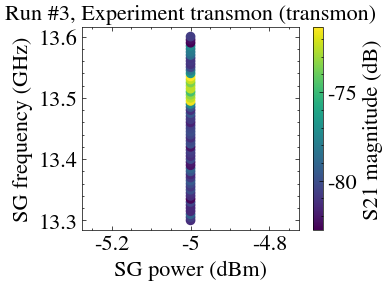

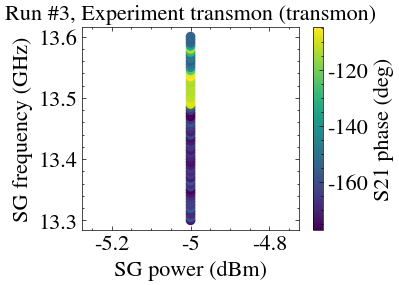

In [ ]:
from qcodes.dataset import load_by_id, plot_dataset

ds = load_by_id(3)
axes, cbars = plot_dataset(ds) 

In [134]:
##optimizado para medir una sola vez en vez de dos

import time
import numpy as np
from qcodes.dataset import Measurement

# ---------------- Parámetros ----------------
pw_sg = np.arange(-5, -21, -1)             # dBm



f0_vna = 8.17172e9
pow_vna = -20
bw_vna = 1
N_points = 1
att_vna = -62
att_sg = 0

start = 13.4e9
stop  = 14.1e9
step  = 500e3

pna.points(N_points)
pna.if_bandwidth(bw_vna)
pna.power(pow_vna)
pna.sweep_type('CW')
pna.cw(f0_vna)

freq_sig = np.arange(start, stop + step, step)

wait = 1.0        # s
N = 1             # number of averages
# --------------------------------------------


meas = Measurement()

traces = pna.traces

meas.register_custom_parameter('pow_sg', label='SG power', unit='dBm')
meas.register_custom_parameter('f_sg', label='SG frequency', unit='GHz')
meas.register_custom_parameter('s21_mag', label='S21 magnitude', unit='dB', setpoints=('pow_sg', 'f_sg'))
meas.register_custom_parameter('s21_phase', label='S21 phase', unit='deg', setpoints=('pow_sg', 'f_sg'))


run_id = None
prev_mode = pna.sweep_mode()      # para devolver el VNA a como estaba
pna.auto_sweep(False)             # leer trazas NO dispara barridos

sg.rf_output(True)

try:

    with meas.run() as datasaver:

        ds = datasaver.dataset

        # Metadata
        ds.add_metadata('f0_vna', f0_vna)
        ds.add_metadata('pow_vna', pow_vna)
        ds.add_metadata('bw_vna', bw_vna)
        ds.add_metadata('att_vna', att_vna)
        ds.add_metadata('att_sg', att_sg)
        ds.add_metadata('N_average', N)

        run_id = datasaver.run_id
        print('run_id:', run_id)

        # =====================================================
        # POWER LOOP
        # =====================================================

        for p in pw_sg:

            print(f'\nPower = {p:.1f} dBm')

            sg.power(p)

            # =================================================
            # FREQUENCY LOOP
            # =================================================

            for f in freq_sig:

                # Set signal-generator frequency
                sg.frequency(f)

                # Wait for the system to settle
                time.sleep(wait)

                # ---------------------------------------------
                # Acquire N measurements (UN barrido por muestra)
                # ---------------------------------------------

                mag_samples = []
                phase_samples = []

                for _ in range(N):

                    traces.tr1.run_sweep()          # un barrido (todas las trazas del canal)

                    mag = traces.tr1.magnitude()    # solo lee
                    phase = traces.tr2.phase()      # solo lee, mismo barrido

                    mag_samples.append(mag)
                    phase_samples.append(phase)

                # ---------------------------------------------
                # Average
                # ---------------------------------------------

                mag_avg = np.mean(mag_samples)
                phase_avg = np.mean(phase_samples)

                # ---------------------------------------------
                # Save
                # ---------------------------------------------

                datasaver.add_result(
                    ('pow_sg', p),
                    ('f_sg', f / 1e9),
                    ('s21_mag', mag_avg),
                    ('s21_phase', phase_avg),
                )

                print(
                    f'f = {f/1e9:.4f} GHz | '
                    f'S21 = {mag_avg:.3f} dB | '
                    f'phase = {phase_avg:.2f} deg'
                )

finally:

    sg.rf_output(False)
    pna.auto_sweep(True)          # volver al comportamiento normal
    pna.sweep_mode(prev_mode)     # el VNA vuelve a barrer en pantalla

print('listo, run_id:', run_id)

Starting experimental run with id: 17. 
run_id: 17

Power = -5.0 dBm
f = 13.4000 GHz | S21 = -80.525 dB | phase = -92.85 deg
f = 13.4005 GHz | S21 = -80.347 dB | phase = -76.69 deg
f = 13.4010 GHz | S21 = -81.125 dB | phase = -76.74 deg
f = 13.4015 GHz | S21 = -81.202 dB | phase = -88.35 deg
f = 13.4020 GHz | S21 = -79.509 dB | phase = -82.70 deg
f = 13.4025 GHz | S21 = -81.526 dB | phase = -88.73 deg
f = 13.4030 GHz | S21 = -80.084 dB | phase = -89.69 deg
f = 13.4035 GHz | S21 = -82.257 dB | phase = -77.97 deg
f = 13.4040 GHz | S21 = -81.522 dB | phase = -89.62 deg
f = 13.4045 GHz | S21 = -80.339 dB | phase = -91.12 deg
f = 13.4050 GHz | S21 = -80.451 dB | phase = -89.00 deg
f = 13.4055 GHz | S21 = -80.917 dB | phase = -87.89 deg
f = 13.4060 GHz | S21 = -81.151 dB | phase = -82.86 deg
f = 13.4065 GHz | S21 = -80.408 dB | phase = -85.57 deg
f = 13.4070 GHz | S21 = -80.316 dB | phase = -97.60 deg
f = 13.4075 GHz | S21 = -80.290 dB | phase = -93.44 deg
f = 13.4080 GHz | S21 = -81.107 dB 

# Para barrer en freq del sg y en freq del vna a potencia fija del sg y con frecuencias del sg alrededor de las lienas espectrales de interes

In [ ]:
import numpy as np
from qcodes.dataset import Measurement, plot_dataset

# ---------------- Parámetros ----------------
###OPTIMIZAR BIEN EL BARRIDO EN FREQ DE VNA PARA QUE NO TARDE INFINITO :)


## vna (barrido lineal)
f0_vna   = 8.23153e9      # Hz, centro del barrido
span     = 7e6           # Hz                     
pow_vna  = -20            # dBm
bw_vna   = 5              # Hz  (ojo: tiempo de barrido ~ N_points / bw_vna)
N_points = 601            # puntos del barrido del VNA
att_vna  = -62

## sg
pw_sg  = -12              # dBm, potencia fija
att_sg = 0
start  = 13.46e9
stop   = 14.1e9
step   = 1e6
freq_sig = np.arange(start, stop + step, step)

wait = 1.0                # s, asentamiento del SG
N = 1                     # promedios (los hace el VNA)
# --------------------------------------------

# ---- Configuración del VNA ----
pna.sweep_type('LIN')
set_params(center=f0_vna, span=span, power=pow_vna, bw=bw_vna, N_points=N_points)
# pna.trigger_source('IMM')
pna.averages(N)
pna.averages_enabled(N > 1)

traces = pna.traces
f_vna = pna.frequency_axis()          # Hz, eje del barrido del VNA (no dispara barrido)

# ---- Estimación de tiempo ----
t_sweep = pna.sweep_time() * N
t_total = len(freq_sig) * (wait + t_sweep)
print(f'{len(freq_sig)} frecuencias SG x {N_points} puntos VNA')
print(f'barrido VNA ~{t_sweep:.1f} s -> total estimado ~{t_total / 3600:.1f} h')

# ---- Registro: x = f_vna, y = f_sg ----
meas = Measurement()
meas.register_custom_parameter('f_vna', label='VNA frequency', unit='GHz')
meas.register_custom_parameter('f_sg', label='SG frequency', unit='GHz')
meas.register_custom_parameter('s21_mag', label='S21 magnitude', unit='dB', setpoints=('f_vna', 'f_sg'))
meas.register_custom_parameter('s21_phase', label='S21 phase', unit='deg', setpoints=('f_vna', 'f_sg'))

run_id = None
prev_mode = pna.sweep_mode()      # para devolver el VNA a como estaba
pna.auto_sweep(False)             # leer trazas NO dispara barridos

try:
    sg.power(pw_sg)
    sg.rf_output(True)

    with meas.run() as datasaver:

        ds = datasaver.dataset
        ds.add_metadata('f0_vna', f0_vna)
        ds.add_metadata('span_vna', span)
        ds.add_metadata('pow_vna', pow_vna)
        ds.add_metadata('bw_vna', bw_vna)
        ds.add_metadata('N_points', N_points)
        ds.add_metadata('att_vna', att_vna)
        ds.add_metadata('pow_sg', pw_sg)
        ds.add_metadata('att_sg', att_sg)
        ds.add_metadata('N_average', N)

        run_id = datasaver.run_id
        print('run_id:', run_id)
        t0 = time.time()

        # =================================================
        # FREQUENCY LOOP (SG)
        # =================================================
        for i, f in enumerate(freq_sig):

            sg.frequency(f)
            time.sleep(wait)

            traces.tr1.run_sweep()            # UN barrido (todas las trazas del canal)
            mag = traces.tr1.magnitude()      # array de N_points, solo lee
            phase = traces.tr2.phase()        # array de N_points, mismo barrido

            datasaver.add_result(
                ('f_vna', f_vna / 1e9),
                ('f_sg', np.full(len(f_vna), f / 1e9)),
                ('s21_mag', mag),
                ('s21_phase', phase),
            )

            if i % 20 == 0 or i == len(freq_sig) - 1:
                el = time.time() - t0
                rest = el / (i + 1) * (len(freq_sig) - i - 1)
                print(f'f_sg = {f/1e9:.4f} GHz ({i + 1}/{len(freq_sig)}) | 'f'min |S21| = {np.min(mag):.2f} dB | ' f'{el / 60:.1f} min, faltan ~{rest / 60:.1f} min')

finally:
    sg.rf_output(False)
    pna.auto_sweep(True)          # volver al comportamiento normal
    pna.sweep_mode(prev_mode)     # el VNA vuelve a barrer en pantalla

print('listo, run_id:', run_id)



641 frecuencias SG x 601 puntos VNA
barrido VNA ~106.2 s -> total estimado ~19.1 h
Starting experimental run with id: 303. 
run_id: 303


[pna_tr1(KeysightPNATrace)] User abort detected. 
An exception occurred in measurement with guid: a2962154-0000-0000-0000-01a12c632046;
Traceback:
Traceback (most recent call last):
  File "C:\Users\Leandro\AppData\Local\Temp\ipykernel_1368\1047016010.py", line 84, in <module>
    traces.tr1.run_sweep()            # UN barrido (todas las trazas del canal)
  File "c:\Users\Leandro\anaconda3\envs\quantum\lib\site-packages\qcodes\instrument_drivers\Keysight\N52xx.py", line 332, in run_sweep
    time.sleep(0.1)
KeyboardInterrupt



KeyboardInterrupt: 

In [ ]:
traces.tr2.phase()

array([26.23659134])

In [ ]:
# ---------------- Parámetros ----------------
pw_sg = np.arange(-5, -21, -0.5)                       # dBm
start, stop, step = 10.44e9, 10.54e9, 0.001e9              # GHz
freq_sig = np.arange(start, stop + step/2, step) 

In [ ]:
len(pw_sg)

32

## only for CW meas


In [ ]:
pna.sweep_type('CW')
pna.sweep_mode('CONT')

In [ ]:
pw1 = np.arange(0,-31,-1)
pw1

array([  0,  -1,  -2,  -3,  -4,  -5,  -6,  -7,  -8,  -9, -10, -11, -12,
       -13, -14, -15, -16, -17, -18, -19, -20, -21, -22, -23, -24, -25,
       -26, -27, -28, -29, -30])

##  pna power sweep

In [ ]:

# f0 = 2.771615e9; bw = 50; N_points = 2001; span = 5e6; power_vna = -30   #r6
# f0 = 2.944545e9; bw = 50; N_points = 2001; span = 8e6; power_vna = -10 #r7

f0 = 2.61392e9; bw = 200; N_points = 2001; span = 8e6; power_vna = -10 #r3

pw1 = np.arange(0,-31,-1)

meas = Measurement()
traces = pna.traces


meas.register_parameter(traces.tr1.magnitude)
meas.register_parameter(traces.tr2.unwrapped_phase)
meas.register_custom_parameter('bw', label='bw', unit='Hz', paramtype='numeric')  # independent
meas.register_custom_parameter('pow', label='pow', unit='dBm', paramtype='numeric')  # independent



t_start = time.time()
last_id = None

with tqdm( total=len(pw1), desc="VNA sweep", unit="power",  dynamic_ncols=True) as pbar:

    for p in pw1:

        t0 = time.time()

        set_params(center=f0,span=span, power=p, bw=bw,N_points=N_points)

        with meas.run() as datasaver:

            mag = traces.tr1.magnitude()
            phase = traces.tr2.unwrapped_phase()

            datasaver.add_result(
                (traces.tr1.magnitude, mag),
                (traces.tr2.unwrapped_phase, phase),
                ('pow', p),
                ('bw', bw),
            )

            last_id = datasaver.run_id

        
        elapsed_point = time.time() - t0
        elapsed_total = time.time() - t_start

        pbar.set_postfix({
            'P (dBm)': f'{p:.0f}',
            't/punto': f'{elapsed_point:.1f} s',
            'tiempo': f'{elapsed_total/60:.1f} min'
        })
        pbar.update(1)

t_total = time.time() - t_start

print(f"\nMedición finalizada.")
print(f"Tiempo total: {t_total/60:.2f} min")
print(f"Tiempo promedio por punto: {t_total/len(pw1):.2f} s")
print(f"Último run_id: {last_id}")

VNA sweep:   0%|          | 0/31 [00:00<?, ?power/s]

Starting experimental run with id: 261. 
Starting experimental run with id: 262. 
Starting experimental run with id: 263. 
Starting experimental run with id: 264. 
Starting experimental run with id: 265. 
Starting experimental run with id: 266. 
Starting experimental run with id: 267. 
Starting experimental run with id: 268. 
Starting experimental run with id: 269. 
Starting experimental run with id: 270. 
Starting experimental run with id: 271. 
Starting experimental run with id: 272. 
Starting experimental run with id: 273. 
Starting experimental run with id: 274. 
Starting experimental run with id: 275. 
Starting experimental run with id: 276. 
Starting experimental run with id: 277. 
Starting experimental run with id: 278. 
Starting experimental run with id: 279. 
Starting experimental run with id: 280. 
Starting experimental run with id: 281. 
Starting experimental run with id: 282. 
Starting experimental run with id: 283. 
Starting experimental run with id: 284. 
Starting experim

[pna_tr1(KeysightPNATrace)] User abort detected. 
An exception occurred in measurement with guid: 02f7fa7e-0000-0000-0000-01a121f6db07;
Traceback:
Traceback (most recent call last):
  File "C:\Users\Leandro\AppData\Local\Temp\ipykernel_1368\2890069736.py", line 32, in <module>
    mag = traces.tr1.magnitude()
  File "c:\Users\Leandro\anaconda3\envs\quantum\lib\site-packages\qcodes\parameters\parameter_base.py", line 523, in __call__
    return self.get()
  File "c:\Users\Leandro\anaconda3\envs\quantum\lib\site-packages\qcodes\parameters\parameter_base.py", line 723, in get_wrapper
    raw_value = get_function(*args, **kwargs)
  File "c:\Users\Leandro\anaconda3\envs\quantum\lib\site-packages\qcodes\instrument_drivers\Keysight\N52xx.py", line 128, in get_raw
    prev_mode = self.instrument.run_sweep()
  File "c:\Users\Leandro\anaconda3\envs\quantum\lib\site-packages\qcodes\instrument_drivers\Keysight\N52xx.py", line 332, in run_sweep
    time.sleep(0.1)
KeyboardInterrupt



KeyboardInterrupt: 

In [ ]:

f0 = 2.782705e9; bw = 50; N_points = 2001; span = 5e6; power_vna = -30
pw1 = np.arange(0,-31,-1)

meas = Measurement()
traces = pna.traces


meas.register_parameter(traces.tr1.magnitude)
meas.register_parameter(traces.tr2.unwrapped_phase)
meas.register_custom_parameter('bw', label='bw', unit='Hz', paramtype='numeric')  # independent
meas.register_custom_parameter('pow', label='pow', unit='dBm', paramtype='numeric')  # independent



t_start = time.time()
last_id = None

with tqdm( total=len(pw1), desc="VNA sweep", unit="power",  dynamic_ncols=True) as pbar:

    for p in pw1:

        t0 = time.time()

        set_params(center=f0,span=span, power=p, bw=bw,N_points=N_points)

        with meas.run() as datasaver:

            mag = traces.tr1.magnitude()
            phase = traces.tr2.unwrapped_phase()

            datasaver.add_result(
                (traces.tr1.magnitude, mag),
                (traces.tr2.unwrapped_phase, phase),
                ('pow', p),
                ('bw', bw),
            )

            last_id = datasaver.run_id

        
        elapsed_point = time.time() - t0
        elapsed_total = time.time() - t_start

        pbar.set_postfix({
            'P (dBm)': f'{p:.0f}',
            't/punto': f'{elapsed_point:.1f} s',
            'tiempo': f'{elapsed_total/60:.1f} min'
        })
        pbar.update(1)

t_total = time.time() - t_start

print(f"\nMedición finalizada.")
print(f"Tiempo total: {t_total/60:.2f} min")
print(f"Tiempo promedio por punto: {t_total/len(pw1):.2f} s")
print(f"Último run_id: {last_id}")

VNA sweep:   0%|          | 0/31 [00:00<?, ?power/s]

Starting experimental run with id: 166. 
Starting experimental run with id: 167. 
Starting experimental run with id: 168. 
Starting experimental run with id: 169. 
Starting experimental run with id: 170. 
Starting experimental run with id: 171. 
Starting experimental run with id: 172. 
Starting experimental run with id: 173. 
Starting experimental run with id: 174. 
Starting experimental run with id: 175. 
Starting experimental run with id: 176. 
Starting experimental run with id: 177. 
Starting experimental run with id: 178. 
Starting experimental run with id: 179. 
Starting experimental run with id: 180. 
Starting experimental run with id: 181. 
Starting experimental run with id: 182. 
Starting experimental run with id: 183. 
Starting experimental run with id: 184. 
Starting experimental run with id: 185. 
Starting experimental run with id: 186. 
Starting experimental run with id: 187. 
Starting experimental run with id: 188. 
Starting experimental run with id: 189. 
Starting experim

[pna_tr2(KeysightPNATrace)] User abort detected. 
An exception occurred in measurement with guid: 5810a1be-0000-0000-0000-01a121a98e65;
Traceback:
Traceback (most recent call last):
  File "C:\Users\Leandro\AppData\Local\Temp\ipykernel_1368\4139545578.py", line 29, in <module>
    phase = traces.tr2.unwrapped_phase()
  File "c:\Users\Leandro\anaconda3\envs\quantum\lib\site-packages\qcodes\parameters\parameter_base.py", line 523, in __call__
    return self.get()
  File "c:\Users\Leandro\anaconda3\envs\quantum\lib\site-packages\qcodes\parameters\parameter_base.py", line 723, in get_wrapper
    raw_value = get_function(*args, **kwargs)
  File "c:\Users\Leandro\anaconda3\envs\quantum\lib\site-packages\qcodes\instrument_drivers\Keysight\N52xx.py", line 128, in get_raw
    prev_mode = self.instrument.run_sweep()
  File "c:\Users\Leandro\anaconda3\envs\quantum\lib\site-packages\qcodes\instrument_drivers\Keysight\N52xx.py", line 332, in run_sweep
    time.sleep(0.1)
KeyboardInterrupt



KeyboardInterrupt: 

# STARK SHIFT

In [143]:

path2database = "stark_shift"
initialise_or_create_database_at(path2database)
load_or_create_experiment(experiment_name="transmon", sample_name="transmon")



transmon#transmon#1@c:\Users\Leandro\Documents\RF\rf-2026\qubits\stark_shift
----------------------------------------------------------------------------
1-results-1-pow_vna,f_sg,s21_mag,s21_phase-24
2-results-2-pow_vna,f_sg,s21_mag,s21_phase-2
3-results-3-pow_vna,f_sg,s21_mag,s21_phase-82
4-results-4-pow_vna,f_sg,s21_mag,s21_phase-240
5-results-5-pow_vna,f_sg,s21_mag,s21_phase-24060
6-results-6-pna_frequency_axis,pna_tr1_magnitude,pna_tr2_unwrapped_phase,bw,pow-0
7-results-7-pna_frequency_axis,pna_tr1_magnitude,pna_tr2_unwrapped_phase,bw,pow-4

In [ ]:
## monitoreamos el modo 1 del resonador r1 ligeramente detuneado y barremos en power vna  y frecuencia del drive del qubit a baja potencia 

### STARK SHIFT y escalera de fotones



import time
import numpy as np
from qcodes.dataset import Measurement

# ---------------- Parámetros ----------------
pow_vna = np.arange(0, -15, -0.5)             # dBm

f0_vna = (7.289085+0.001)*1e9

bw_vna = 1
N_points = 1
att_vna = -62
att_sg = 0

f_start = 10.4e9
f_stop = 10.6e9
step = 500e3

pow_sg = -20


pna.points(N_points)
pna.if_bandwidth(bw_vna)
#pna.sweep_type('CW')
pna.cw(f0_vna)

freq_sig = np.arange(f_start, f_stop + step, step)

wait = 1.0        # s
N = 1             # number of averages
# --------------------------------------------


meas = Measurement()

traces = pna.traces

meas.register_custom_parameter('pow_vna', label='VNA power', unit='dBm')
meas.register_custom_parameter('f_sg', label='SG frequency', unit='GHz')
meas.register_custom_parameter('s21_mag', label='S21 magnitude', unit='dB', setpoints=('pow_vna', 'f_sg'))
meas.register_custom_parameter('s21_phase', label='S21 phase', unit='deg', setpoints=('pow_vna', 'f_sg'))



sg.rf_output(True)

try:

    with meas.run() as datasaver:

        ds = datasaver.dataset

        # Metadata
        ds.add_metadata('f0_vna', f0_vna)
        ds.add_metadata('pow_sg', pow_sg)
        ds.add_metadata('bw_vna', bw_vna)
        ds.add_metadata('att_vna', att_vna)
        ds.add_metadata('att_sg', att_sg)
        ds.add_metadata('N_average', N)

        run_id = datasaver.run_id
        print('run_id:', run_id)

        # =====================================================
        # POWER LOOP
        # =====================================================

        for p in pow_vna:

            print(f'\nPower = {p:.1f} dBm en vna')

            pna.power(p) #seteo la potencia en el vna

            # =================================================
            # FREQUENCY LOOP
            # =================================================

            for f in freq_sig:

                # Set signal-generator frequency
                sg.frequency(f)

                # Wait for the system to settle
                time.sleep(wait)

                # ---------------------------------------------
                # Acquire N measurements
                # ---------------------------------------------

                mag_samples = []
                phase_samples = []

                for _ in range(N):

                    mag = traces.tr1.magnitude()
                    phase = traces.tr2.phase()

                    mag_samples.append(mag)
                    phase_samples.append(phase)

                    time.sleep(0.01)

                # ---------------------------------------------
                # Average
                # ---------------------------------------------

                mag_avg = np.mean(mag_samples)
                phase_avg = np.mean(phase_samples)

                
                # ---------------------------------------------
                # Save
                # ---------------------------------------------

                datasaver.add_result(
                    ('pow_vna', p),
                    ('f_sg', f / 1e9),
                    ('s21_mag', mag_avg),
                    ('s21_phase', phase_avg),
                )

                print(
                    f'f = {f/1e9:.3f} GHz | '
                    f'S21 = {mag_avg:.3f} dB | '
                    f'phase = {phase_avg:.2f} deg'
                )

finally:

    sg.rf_output(False)

print('listo, run_id:', run_id)

Starting experimental run with id: 5. 
run_id: 5

Power = 0.0 dBm en vna
f = 10.400 GHz | S21 = -80.487 dB | phase = -21.53 deg
f = 10.400 GHz | S21 = -80.415 dB | phase = -21.65 deg
f = 10.401 GHz | S21 = -80.482 dB | phase = -21.74 deg
f = 10.402 GHz | S21 = -80.430 dB | phase = -21.45 deg
f = 10.402 GHz | S21 = -80.478 dB | phase = -21.43 deg
f = 10.402 GHz | S21 = -80.546 dB | phase = -21.42 deg
f = 10.403 GHz | S21 = -80.435 dB | phase = -21.68 deg
f = 10.403 GHz | S21 = -80.455 dB | phase = -21.50 deg
f = 10.404 GHz | S21 = -80.387 dB | phase = -21.60 deg
f = 10.405 GHz | S21 = -80.450 dB | phase = -21.82 deg
f = 10.405 GHz | S21 = -80.459 dB | phase = -21.76 deg
f = 10.405 GHz | S21 = -80.454 dB | phase = -21.34 deg
f = 10.406 GHz | S21 = -80.459 dB | phase = -22.32 deg
f = 10.406 GHz | S21 = -80.343 dB | phase = -21.47 deg
f = 10.407 GHz | S21 = -80.378 dB | phase = -21.94 deg
f = 10.408 GHz | S21 = -80.434 dB | phase = -21.96 deg
f = 10.408 GHz | S21 = -80.453 dB | phase = -21

In [63]:
path2database = "stark_shift"
initialise_or_create_database_at(path2database)

In [144]:
from qcodes.dataset import load_by_id, plot_dataset



%matplotlib tk
ds = load_by_id(5)
axes, cbars = plot_dataset(ds) 


# ds = load_by_id(4)
# xds = ds.to_xarray_dataset()
# print(xds)          # para ver cómo se llaman las coordenadas (pow_vna o pow_sg)

# p = 0         # potencia que querés ver [dBm]
# corte = xds.sel(pow_vna=p, method='nearest')   # la más cercana a p

# fig, ax = plt.subplots(2, 1, sharex=True, figsize=(7, 5))
# corte.s21_mag.plot(ax=ax[0], marker='.')
# corte.s21_phase.plot(ax=ax[1], marker='.')
# ax[0].set_title(f'run 4, potencia = {float(corte.pow_vna):.1f} dBm')
# fig.tight_layout()
# plt.show()

In [145]:
import matplotlib.pyplot as plt
from qcodes.dataset import load_by_id
from lorentzian_fit_stark_shift import (load_grid, crop_grid, fit_all, plot_row_fit, plot_map_with_centers, width_vs_power)

ds = load_by_id(5)
g  = load_grid(ds, z='s21_mag')                 # better: z='s21_phase' for widths (see below)
gc = crop_grid(g, power=(-20, -4))              # VNA powers between -20 and -4 dBm

res = fit_all(gc, window=(10.4, 10.6))
plot_map_with_centers(gc, res)

plot_row_fit(gc, res, power=-12)

out = width_vs_power(res)                       # FWHM vs P_VNA (mW), extrapolated to P = 0
plt.show()

22/22 rows fitted
peak 0: f0 = 10.482185 ± 7.7e-05, FWHM = 1.545e-03, A = 1.07
FWHM(P) = 2.0850 ± 0.1107 MHz + (4.612e-01 ± 4.1e-01) MHz/mW * P
Extrapolated to P = 0:  T2 ≈ 153 ± 8 ns   ->   T1 ≥ 76 ns


### Two tone spectroscopy

In [ ]:
pow_sg = 0
span_sg = 8e9
f0_sg = 12.0e9
step_sg = 3e6
freq_sig = np.arange(f0_sg-span_sg/2, f0_sg+span_sg/2, step_sg)

f0_vna = 8.174e9
pow_vna = -30
bw_vna = 1
N_points=1 #toma puntos cada 1 s
att_vna = -62
att_sg = 0
span_vna = 100e6




In [ ]:
from qcodes.instrument_drivers.Keysight.Keysight_N5173B import KeysightN5173B

In [ ]:
sg = KeysightN5173B(name="n5173b", address="GPIB1::19::INSTR")

In [ ]:
pna.if_bandwidth(1)
pna.points(1)

In [ ]:
from qcodes.instrument_drivers.Keysight.Keysight_N5173B import KeysightN5173B

In [ ]:
sg = KeysightN5173B(name="n5173b", address="GPIB1::19::INSTR")

In [ ]:
sg.power(pow_sg)
for f in freq_sig:
    sg.frequency(f)
    plt.pause(1)


KeyboardInterrupt: 

In [ ]:
#en esta version hay un id para cada corrida
meas = Measurement()
traces = pna.traces

meas.register_parameter(traces.tr1.magnitude)
meas.register_parameter(traces.tr2.unwrapped_phase)
meas.register_custom_parameter('bw', label='bw', unit='Hz', paramtype='numeric')  # independent
meas.register_custom_parameter('pow_vna', label='pow_vna', unit='dBm', paramtype='numeric')  # independent
meas.register_custom_parameter('pow_sg', label='pow_sg', unit='dBm', paramtype='numeric')  # independent
meas.register_custom_parameter('att_vna', label='att_vna', unit='dBm', paramtype='numeric')  # independent
meas.register_custom_parameter('att_sg', label='att_sg', unit='dBm', paramtype='numeric')  # independent

set_params(center=f0_vna, span=span_vna, power=pow_vna, bw=bw_vna, N_points=N_points)
sg.power(pow_sg)


for f in freq_sig:
    sg.frequency(f)        
    with meas.run() as datasaver:
            #set_params(center, span, pow_vna=-5, bw, N_points)
            traces.tr1.run_sweep()
            traces.tr2.run_sweep()

            mag = traces.tr1.magnitude()
            phase = traces.tr2.unwrapped_phase()
            datasaver.add_result(
                (traces.tr1.magnitude, mag),
                (traces.tr2.unwrapped_phase, phase),
                ('pow_vna', pow_vna),
                ('pow_sg', pow_sg),
                ('bw', bw),
                ('att_sg', att_sg),
                ('att_vna', att_vna),
            )
            last_id = datasaver.run_id
    
#plot_by_id(last_id)

In [ ]:
sg.rf_output(False)

In [ ]:
##version para que todo quede bajo el mismo id

meas = Measurement()
traces = pna.traces

# Eje que barrés: frecuencia del generador
meas.register_custom_parameter('f_sg', label='f_sg', unit='Hz', paramtype='numeric')

# Magnitud y fase dependen de f_sg (más el eje de frecuencia propio del VNA)
meas.register_parameter(traces.tr1.magnitude, setpoints=('f_sg',))
meas.register_parameter(traces.tr2.unwrapped_phase, setpoints=('f_sg',))

set_params(center=f0_vna, span=span_vna, power=pow_vna, bw=bw_vna, N_points=N_points)
sg.power(pow_sg)
sg.rf_output(True)

with meas.run() as datasaver:
    # Parámetros fijos como metadata del run
    ds = datasaver.dataset
    ds.add_metadata('f0_vna', f0_vna)
    ds.add_metadata('pow_vna', pow_vna)
    ds.add_metadata('bw_vna', bw_vna)
    ds.add_metadata('span_vna', span_vna)
    ds.add_metadata('pow_sg', pow_sg)
    ds.add_metadata('att_vna', att_vna)
    ds.add_metadata('att_sg', att_sg)

    for f in freq_sig:
        sg.frequency(f)
        time.sleep(0.05)  #le da tiempo al generador de estabilizarse

        traces.tr1.run_sweep()
        traces.tr2.run_sweep()

        mag = traces.tr1.magnitude()
        phase = traces.tr2.unwrapped_phase()

        datasaver.add_result(
            ('f_sg', f),
            (traces.tr1.magnitude, mag),
            (traces.tr2.unwrapped_phase, phase),
        )

    run_id = datasaver.run_id

print('run_id:', run_id)

Starting experimental run with id: 444. 


[pna_tr2(KeysightPNATrace)] User abort detected. 
An exception occurred in measurement with guid: 1f3057a3-0000-0000-0000-01a10d07d030;
Traceback:
Traceback (most recent call last):
  File "C:\Users\Leandro\AppData\Local\Temp\ipykernel_14904\4063446351.py", line 33, in <module>
    traces.tr2.run_sweep()
  File "c:\Users\Leandro\anaconda3\envs\quantum\lib\site-packages\qcodes\instrument_drivers\Keysight\N52xx.py", line 332, in run_sweep
    time.sleep(0.1)
KeyboardInterrupt



KeyboardInterrupt: 

In [ ]:
pow_sg = 0
span_sg = 8e9
f0_sg = 12.0e9
step_sg = 3e6
freq_sig = np.arange(f0_sg-span_sg/2, f0_sg+span_sg/2, step_sg)

f0_vna = 7.2884e9
pow_vna = -30
bw_vna = 1
N_points=1 #toma puntos cada 1 s
att_vna = -62
att_sg = -72
span_vna = 100e6

sg.power(pow_sg)

for i, f in enumerate(freq_sig):
        sg.frequency(f)
        time.sleep(1.0)

KeyboardInterrupt: 

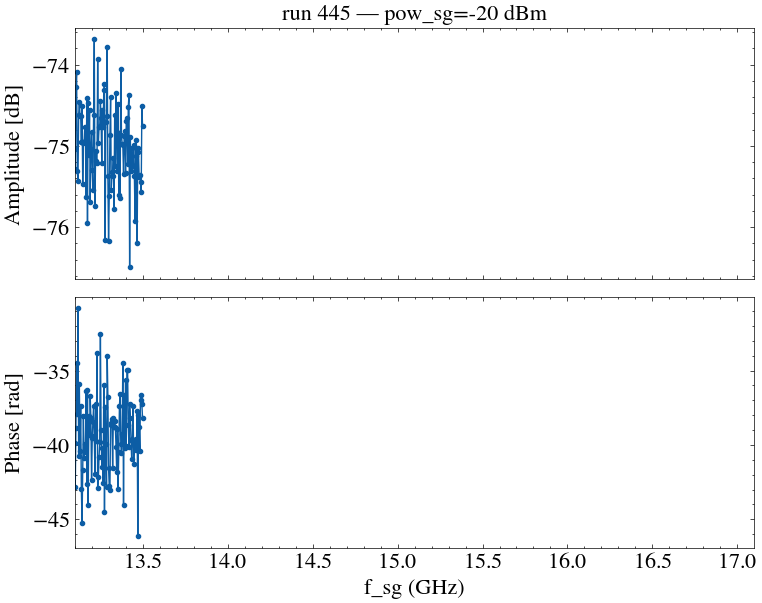

Starting experimental run with id: 445. 


[pna_tr1(KeysightPNATrace)] User abort detected. 
An exception occurred in measurement with guid: f6cbdc3f-0000-0000-0000-01a10d0bb4b5;
Traceback:
Traceback (most recent call last):
  File "C:\Users\Leandro\AppData\Local\Temp\ipykernel_14904\1165175030.py", line 39, in <module>
    mag = traces.tr1.magnitude()
  File "c:\Users\Leandro\anaconda3\envs\quantum\lib\site-packages\qcodes\parameters\parameter_base.py", line 523, in __call__
    return self.get()
  File "c:\Users\Leandro\anaconda3\envs\quantum\lib\site-packages\qcodes\parameters\parameter_base.py", line 723, in get_wrapper
    raw_value = get_function(*args, **kwargs)
  File "c:\Users\Leandro\anaconda3\envs\quantum\lib\site-packages\qcodes\instrument_drivers\Keysight\N52xx.py", line 128, in get_raw
    prev_mode = self.instrument.run_sweep()
  File "c:\Users\Leandro\anaconda3\envs\quantum\lib\site-packages\qcodes\instrument_drivers\Keysight\N52xx.py", line 332, in run_sweep
    time.sleep(0.1)
KeyboardInterrupt



KeyboardInterrupt: 

In [ ]:
from IPython.display import display

# --- Figura en vivo ---
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(8, 6))
line_mag, = ax[0].plot([], [], '.-')
line_pha, = ax[1].plot([], [], '.-')
ax[0].set_ylabel('Amplitude [dB]')
ax[1].set_ylabel('Phase [rad]')
ax[1].set_xlabel('f_sg (GHz)')
ax[1].set_xlim(freq_sig[0] / 1e9, freq_sig[-1] / 1e9)
plt.tight_layout()
handle = display(fig, display_id=True)
plt.close(fig)              # evita que aparezca dos veces

f_list, mag_list, pha_list = [], [], []
update_every = 5            # redibujar cada N puntos (más rápido)

sg.rf_output(True)

with meas.run() as datasaver:
    ds = datasaver.dataset
    ds.add_metadata('f0_vna', f0_vna)
    ds.add_metadata('pow_vna', pow_vna)
    ds.add_metadata('bw_vna', bw_vna)
    ds.add_metadata('span_vna', span_vna)
    ds.add_metadata('pow_sg', pow_sg)
    ds.add_metadata('att_vna', att_vna)
    ds.add_metadata('att_sg', att_sg)

    run_id = datasaver.run_id
    ax[0].set_title(f'run {run_id} — pow_sg={pow_sg} dBm')

    for i, f in enumerate(freq_sig):
        sg.frequency(f)

        traces.tr1.run_sweep()
        traces.tr2.run_sweep()

        mag = traces.tr1.magnitude()
        phase = traces.tr2.unwrapped_phase()

        datasaver.add_result(
            ('f_sg', f),
            (traces.tr1.magnitude, mag),
            (traces.tr2.unwrapped_phase, phase),
        )

        # Datos para el plot (promedio por si la traza tiene más de 1 punto)
        f_list.append(f / 1e9)
        mag_list.append(np.mean(mag))
        pha_list.append(np.mean(phase))

        if i % update_every == 0 or i == len(freq_sig) - 1:
            line_mag.set_data(f_list, mag_list)
            line_pha.set_data(f_list, pha_list)
            for a in ax:
                a.relim()
                a.autoscale_view(scalex=False)   # x fijo, y se ajusta solo
            handle.update(fig)

print('run_id:', run_id)

# FLUXONIUM 

In [ ]:
path2database = "fluxonium_database/resonancia_flux"
initialise_or_create_database_at(path2database)
load_or_create_experiment(experiment_name="flux_driven", sample_name="fluxonium")

flux_driven#fluxonium#1@c:\Users\Leandro\Documents\RF\rf-2026\qubits\fluxonium_database\resonancia_flux
-------------------------------------------------------------------------------------------------------
1-results-1-f_vna,current,s21_mag,s21_phase-20402
2-results-2-f_vna,current,s21_mag,s21_phase-20402
3-results-3-f_vna,current,s21_mag,s21_phase-0
4-results-4-f_vna,current,s21_mag,s21_phase-0
5-results-5-f_vna,current,s21_mag,s21_phase-43430
6-results-6-pna_time_axis,pna_tr1_magnitude,pna_tr2_unwrapped_phase,bw,pow-4
7-results-7-pna_frequency_axis,pna_tr1_magnitude,pna_tr2_unwrapped_phase,bw,pow-4
8-results-8-pna_time_axis,pna_tr1_magnitude,pna_tr2_unwrapped_phase,bw,pow-0
9-results-9-pna_frequency_axis,pna_tr1_magnitude,pna_tr2_unwrapped_phase,bw,pow-4
10-results-10-pna_time_axis,pna_tr1_magnitude,pna_tr2_unwrapped_phase,bw,pow-0
11-results-11-pna_frequency_axis,pna_tr1_magnitude,pna_tr2_unwrapped_phase,bw,pow-4
12-results-12-f_vna,current,s21_mag,s21_phase-202
13-results-13-f_sg,

## current source

In [5]:
%matplotlib tk

In [6]:
# Clase para la fuente de corriente
class keithley_current_source():
    def __init__(self, inst):
        self.inst = inst

    def set_current(self, I):
        self.inst.write(f'I{I:.4e}X')
    def get_current(self):
        return float(self.inst.query("CURR?").split(",")[0][4:] )

In [7]:
current_source = rm.open_resource("GPIB0::15::INSTR")


In [8]:
keithley = keithley_current_source(current_source)

In [11]:
station.add_component(keithley)

'component1'

In [12]:
station.components

{'pna': <KeysightN5245A: pna>,
 'component1': <__main__.keithley_current_source at 0x1b589ba3700>}

In [13]:
start = 0e-6
stop  = 100-6

step  = 0.01e-6

currents = np.arange(start, stop+step, step)

len(currents)

MemoryError: Unable to allocate 70.0 GiB for an array with shape (9400000001,) and data type float64

In [ ]:
for c in currents:
    keithley.set_current(c)
    time.sleep(1)

KeyboardInterrupt: 

### Single sweep

In [ ]:
f0 = 7.95e9; bw = 200; N_points = 2001; span = 2e9; power_vna = -20 #r3

Starting experimental run with id: 126. 


([<Axes: title={'center': 'Run #126, Experiment flux_driven (fluxonium)'}, xlabel='Frequency (GHz)', ylabel='Magnitude (dB)'>,
  <Axes: title={'center': 'Run #126, Experiment flux_driven (fluxonium)'}, xlabel='Frequency (GHz)', ylabel='Phase (deg)'>],
 [None, None])

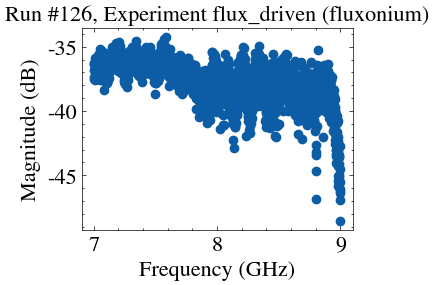

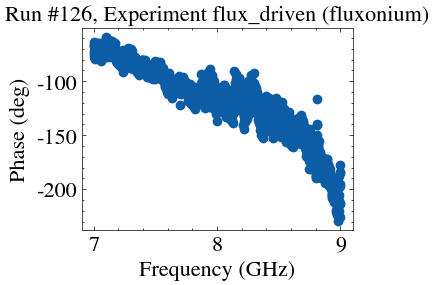

In [ ]:
pna.sweep_type('LIN')
meas = Measurement()
traces = pna.traces

meas.register_parameter(traces.tr1.magnitude)
meas.register_parameter(traces.tr2.unwrapped_phase)
meas.register_custom_parameter('bw', label='bw', unit='Hz', paramtype='numeric')  # independent
meas.register_custom_parameter('pow', label='pow', unit='dBm', paramtype='numeric')  # independent


    
set_params(center=f0, span=span, power=power_vna, bw=bw, N_points=N_points)
pna.auto_sweep(False) 
with meas.run() as datasaver:
        # set_params(center, span, pow_vna=-5, bw, N_points)
        #traces.tr1.run_sweep()
        #traces.tr2.run_sweep()
        prev_mode = traces.tr1.run_sweep()
        mag = traces.tr1.magnitude()
        phase = traces.tr2.unwrapped_phase()
        

        datasaver.add_result(
            (traces.tr1.magnitude, mag),
            (traces.tr2.unwrapped_phase, phase),
            ('pow', power_vna),
            ('bw', bw),
        )
        last_id = datasaver.run_id
    
plot_by_id(last_id)

In [17]:
start = 0e-6
stop  = 70e-6
step  = 0.1e-6

currents = np.arange(start, stop, step)
print(len(currents))

700


### MAG and Phase at CW - Current 

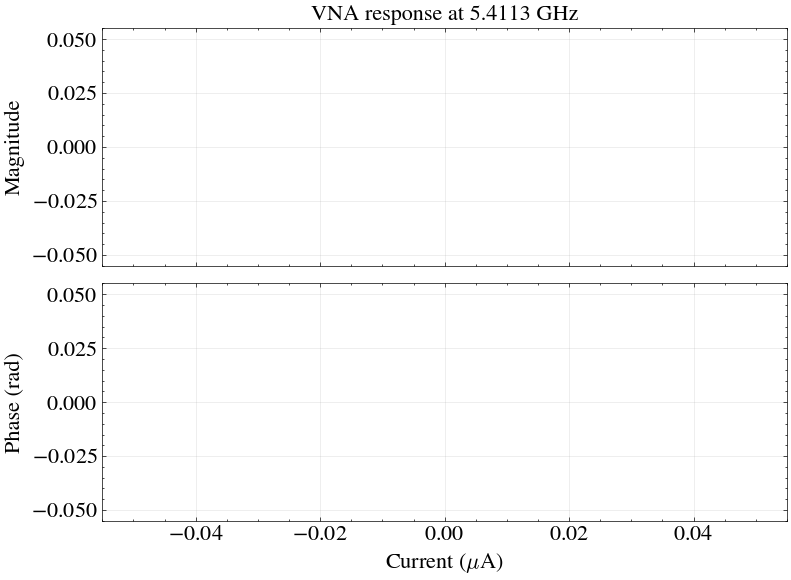

Starting experimental run with id: 26. 
100/100 | I = 199.00 uA | Mag = -72.444 | Phase = 29.944 rad
Medición finalizada. run_id = 26


In [51]:
import time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from qcodes.dataset import Measurement

# ============================================================
# 1. PARÁMETROS DE MEDICIÓN
# ============================================================

f0_vna = 5.4113228e9
pow_vna = -15
bw_vna = 1
N_points = 1
att_vna = -62

start = 100.005e-6
stop  = 200.0e-6
step  = 1e-6

currents = np.arange(start, stop, step)

wait = 0.05  # Tiempo de estabilización (s)

# ============================================================
# 2. CONFIGURACIÓN DEL VNA
# ============================================================

pna.points(N_points)
pna.if_bandwidth(bw_vna)
pna.cw(f0_vna)

traces = pna.traces

# ============================================================
# 3. CONFIGURACIÓN DE QCoDeS
# ============================================================

meas = Measurement()

meas.register_custom_parameter(
    'current',
    label='Current',
    unit='uA',
    paramtype='numeric'
)

meas.register_parameter(
    traces.tr1.magnitude,
    setpoints=('current',)
)

meas.register_parameter(
    traces.tr2.unwrapped_phase,
    setpoints=('current',)
)

# ============================================================
# 4. GRÁFICAS EN TIEMPO REAL
# ============================================================

plt.ion()

fig, ax = plt.subplots(
    2, 1,
    figsize=(8, 6),
    sharex=True
)

line_mag, = ax[0].plot(
    [], [], 'o-', lw=1.5, ms=4
)

line_phase, = ax[1].plot(
    [], [], 'o-', lw=1.5, ms=4
)

ax[0].set_ylabel('Magnitude')
ax[1].set_ylabel('Phase (rad)')
ax[1].set_xlabel(r'Current ($\mu$A)')

ax[0].set_title(
    f'VNA response at {f0_vna/1e9:.4f} GHz'
)

for a in ax:
    a.grid(True, alpha=0.3)

fig.tight_layout()
display(fig)

# Buffers para las gráficas
current_data = []
mag_data = []
phase_data = []

# ============================================================
# 5. MEDICIÓN
# ============================================================

pna.auto_sweep(False) 

with meas.run() as datasaver:

    ds = datasaver.dataset

    # Metadata
    ds.add_metadata('f0_vna', f0_vna)
    ds.add_metadata('pow_vna', pow_vna)
    ds.add_metadata('bw_vna', bw_vna)
    ds.add_metadata('att_vna', att_vna)
    ds.add_metadata('N_points', N_points)
    ds.add_metadata('wait_s', wait)

    for i, c in enumerate(currents):

        # ----------------------------------------
        # Aplicar corriente (A)
        # ----------------------------------------
        keithley.set_current(float(c))

        time.sleep(wait)

        # ----------------------------------------
        # Adquirir magnitud y fase
        # ----------------------------------------
        prev_mode = traces.tr1.run_sweep()
        #traces.tr1.run_sweep()
        #traces.tr2.run_sweep()

        mag = np.asarray(
            traces.tr1.magnitude()
        ).squeeze()

        phase = np.asarray(
            traces.tr2.unwrapped_phase()
        ).squeeze()

        # ----------------------------------------
        # Preparar datos para QCoDeS
        # El driver espera arrays, incluso con 1 punto
        # ----------------------------------------
        mag_array = np.atleast_1d(mag)
        phase_array = np.atleast_1d(phase)

        # Escalares para la gráfica
        mag_value = float(mag_array[0])
        phase_value = float(phase_array[0])

        # Corriente en microamperios
        c_uA = float(c * 1e6)

        # ----------------------------------------
        # Guardar en el mismo dataset
        # ----------------------------------------
        datasaver.add_result(
            ('current', c_uA),
            (traces.tr1.magnitude, mag_array),
            (traces.tr2.unwrapped_phase, phase_array),
        )

        # ----------------------------------------
        # Actualizar datos de las gráficas
        # ----------------------------------------
        current_data.append(c_uA)
        mag_data.append(mag_value)
        phase_data.append(phase_value)

        line_mag.set_data(
            current_data, mag_data
        )

        line_phase.set_data(
            current_data, phase_data
        )

        for a in ax:
            a.relim()
            a.autoscale_view()

        fig.canvas.draw_idle()
        fig.canvas.flush_events()


        # Progreso
        print(
            f'\r{i+1}/{len(currents)} | '
            f'I = {c_uA:.2f} uA | '
            f'Mag = {mag_value:.5g} | '
            f'Phase = {phase_value:.5g} rad',
            end='',
            flush=True
        )

    run_id = datasaver.run_id

# ============================================================
# 6. FINALIZACIÓN
# ============================================================

plt.ioff()
plt.show()

print(f'\nMedición finalizada. run_id = {run_id}')

In [ ]:
%matplotlib tk

In [ ]:
8.8/3

2.9333333333333336

### MAG and Phase sweep f - Current

In [ ]:

sg = KeysightN5173B(name="n5173b", address="GPIB1::19::INSTR")

In [ ]:

station = qc.Station(pna,keithley)

[pna_port3(KeysightPNAPort)] Snapshot: Could not update parameter: source_power
[pna_port4(KeysightPNAPort)] Snapshot: Could not update parameter: source_power
[pna_port3(KeysightPNAPort)] Snapshot: Could not update parameter: source_power
[pna_port4(KeysightPNAPort)] Snapshot: Could not update parameter: source_power


In [23]:
import qcodes as qc

st = qc.Station.default
print('componentes en la Station:', list(st.components))
for name, comp in list(st.components.items()):
    if not hasattr(comp, 'snapshot'):          # lo que no es instrumento QCoDeS
        st.remove_component(name)
        print('sacado de la Station:', name)

componentes en la Station: ['pna', 'component1']
sacado de la Station: component1


In [18]:
f0_vna = 5.98980e9
pow_vna = -30
bw_vna = 100
N_points = 1
att_vna = -62

start = 0e-6
stop  = 100e-6
step  = 0.01e-6

In [21]:
def set_centers(center, span, N_points=2001):
    freq_start = center - span/2
    freq_stop = center + span/2
    pna.start(freq_start)
    pna.stop(freq_stop)
    pna.points(N_points)

def set_power(power):
    pna.power(power)

def set_params(center, span, power, bw, N_points=2001):
    set_centers(center, span, N_points)
    set_power(power)
    pna.if_bandwidth(bw)
    time.sleep(0.1)  # wait for the pna to update settings

In [31]:
I_start = 14e-6      # A
I_stop  = 24e-6  # A (incluido)
I_step  = 0.005e-6           # A (negativo si I_stop < I_start)
currents = np.arange(I_start, I_stop + I_step, I_step)
print(len(currents))

2002


In [33]:
import time
import numpy as np
from qcodes.dataset import Measurement, plot_dataset

# ---------------- Parámetros ----------------
## vna (barrido lineal)
# f0_vna   = 7.95e9 #centro del barrido
# span     = 100e6      # Hz
# pow_vna  = -15           # dBm
# bw_vna   = 20           # Hz  (ojo: tiempo de barrido ~ N_points / bw_vna)
# N_points = 101         # puntos del barrido del VNA
# att_vna  = -62

f0_vna = 5.98980e9
pow_vna = -20
bw_vna = 10
N_points = 101
att_vna = -61
span  = 10e6

## fuente de corriente (bobina de flujo)
I_start = 14.5e-6      # A
I_stop  = 24e-6  # A (incluido)
I_step  = 0.05e-6           # A (negativo si I_stop < I_start)
currents = np.arange(I_start, I_stop + I_step, I_step)
wait_I  = 0.05            # s, estabilización después de cada corriente
rampa_paso = 1e-6         # A, rampa hasta I_start antes de medir (None = directo)
volver_a_cero = False

## sg (fijo durante toda la medición)
usar_sg = False   # False = SG apagado (solo VNA vs flujo)
f_sg   = 13.6e9           # Hz, frecuencia fija
pw_sg  = -12              # dBm, potencia fija
att_sg = 0

N = 1                     # promedios (los hace el VNA)
# --------------------------------------------


def rampa_corriente(objetivo, paso=rampa_paso, espera=0.05):
    """Lleva la corriente al objetivo en pasos chicos (evita saltos de flujo)."""
    if paso is None:
        keithley.set_current(float(objetivo))
        return
    try:
        actual = float(keithley.get_current())
    except Exception:  # noqa: BLE001  (si el driver no tiene get_current)
        actual = 0.0
    n = max(int(np.ceil(abs(objetivo - actual) / paso)), 1)
    for i_ in np.linspace(actual, objetivo, n + 1)[1:]:
        keithley.set_current(float(i_))
        time.sleep(espera)


# ---- Configuración del VNA ----
pna.sweep_type('LIN')
set_params(center=f0_vna, span=span, power=pow_vna, bw=bw_vna, N_points=N_points)
pna.averages(N)
# pna.averages_enabled(N > 1)

traces = pna.traces
f_vna = pna.frequency_axis()          # Hz, eje del barrido del VNA (no dispara barrido)

# ---- Estimación de tiempo ----
t_sweep = pna.sweep_time() * N
t_total = len(currents) * (wait_I + t_sweep)
print(f'{len(currents)} corrientes x {N_points} puntos VNA')
print(f'barrido VNA ~{t_sweep:.1f} s -> total estimado ~{t_total / 3600:.1f} h')

# ---- Registro: x = f_vna, y = corriente ----
meas = Measurement()
meas.register_custom_parameter('f_vna', label='VNA frequency', unit='GHz')
meas.register_custom_parameter('current', label='Current', unit='uA')
meas.register_custom_parameter('s21_mag', label='S21 magnitude', unit='dB', setpoints=('f_vna', 'current'))
meas.register_custom_parameter('s21_phase', label='S21 phase', unit='deg', setpoints=('f_vna', 'current'))

run_id = None
prev_mode = pna.sweep_mode()      # para devolver el VNA a como estaba
pna.auto_sweep(False)             # leer trazas NO dispara barridos

try:
    # llevar la corriente al valor inicial antes de medir
    rampa_corriente(currents[0])
    time.sleep(1.0)

    # if usar_sg:
    #     sg.frequency(f_sg)
    #     sg.power(pw_sg)
    #     sg.rf_output(True)

    with meas.run() as datasaver:

        ds = datasaver.dataset
        ds.add_metadata('f0_vna', f0_vna)
        ds.add_metadata('span_vna', span)
        ds.add_metadata('pow_vna', pow_vna)
        ds.add_metadata('bw_vna', bw_vna)
        ds.add_metadata('N_points', N_points)
        ds.add_metadata('att_vna', att_vna)
        ds.add_metadata('usar_sg', int(usar_sg))
        ds.add_metadata('f_sg', f_sg if usar_sg else np.nan)
        ds.add_metadata('pow_sg', pw_sg if usar_sg else np.nan)
        ds.add_metadata('att_sg', att_sg)
        ds.add_metadata('N_average', N)
        ds.add_metadata('wait_I', wait_I)

        run_id = datasaver.run_id
        print('run_id:', run_id)
        t0 = time.time()

        # =================================================
        # CURRENT LOOP (fuente de corriente)
        # =================================================
        for i, c in enumerate(currents):

            keithley.set_current(float(c))
            time.sleep(wait_I)

            traces.tr1.run_sweep()            # UN barrido (todas las trazas del canal)
            mag = traces.tr1.magnitude()      # array de N_points, solo lee
            phase = traces.tr2.phase()        # array de N_points, mismo barrido

            datasaver.add_result(
                ('f_vna', f_vna / 1e9),
                ('current', np.full(len(f_vna), c * 1e6)),
                ('s21_mag', mag),
                ('s21_phase', phase),
            )

            if i % 20 == 0 or i == len(currents) - 1:
                el = time.time() - t0
                rest = el / (i + 1) * (len(currents) - i - 1)
                print(f'I = {c*1e6:8.2f} uA ({i + 1}/{len(currents)}) | '
                      f'min |S21| = {np.min(mag):.2f} dB | '
                      f'{el / 60:.1f} min, faltan ~{rest / 60:.1f} min')

finally:
    if usar_sg:
        sg.rf_output(False)
    pna.auto_sweep(True)          # volver al comportamiento normal
    pna.sweep_mode(prev_mode)     # el VNA vuelve a barrer en pantalla
    if volver_a_cero:
        rampa_corriente(0.0)

print('listo, run_id:', run_id)

# # ---- Color plots: x = f_vna, y = corriente ----
# if run_id is not None:
#     axes, cbars = plot_dataset(datasaver.dataset)

192 corrientes x 101 puntos VNA
barrido VNA ~8.9 s -> total estimado ~0.5 h
Starting experimental run with id: 8. 
run_id: 8
I =    14.50 uA (1/192) | min |S21| = -71.67 dB | 0.2 min, faltan ~30.5 min


[pna_tr1(KeysightPNATrace)] User abort detected. 
An exception occurred in measurement with guid: 0d3eef8c-0000-0000-0000-01a1b2a20fe3;
Traceback:
Traceback (most recent call last):
  File "C:\Users\Leandro\AppData\Local\Temp\ipykernel_16300\3007005183.py", line 119, in <module>
    traces.tr1.run_sweep()            # UN barrido (todas las trazas del canal)
  File "c:\Users\Leandro\anaconda3\envs\quantum\lib\site-packages\qcodes\instrument_drivers\Keysight\N52xx.py", line 332, in run_sweep
    time.sleep(0.1)
KeyboardInterrupt



KeyboardInterrupt: 

In [ ]:
pna.sweep_type('LIN')

In [ ]:
print(pna.parameters.keys())

dict_keys(['IDN', 'timeout', 'output', 'power', 'if_bandwidth', 'averages_enabled', 'averages', 'start', 'stop', 'center', 'span', 'cw', 'points', 'electrical_delay', 'sweep_time', 'sweep_mode', 'sweep_type', 'group_trigger_count', 'trigger_source', 'frequency_axis', 'frequency_log_axis', 'time_axis', 'active_trace', 'trace', 'format', 'magnitude', 'linear_magnitude', 'phase', 'unwrapped_phase', 'group_delay', 'real', 'imaginary', 'polar', 'auto_sweep'])


### Two tone with current - final code

212 corrientes x (101 pts LIN + 801 pts SG)


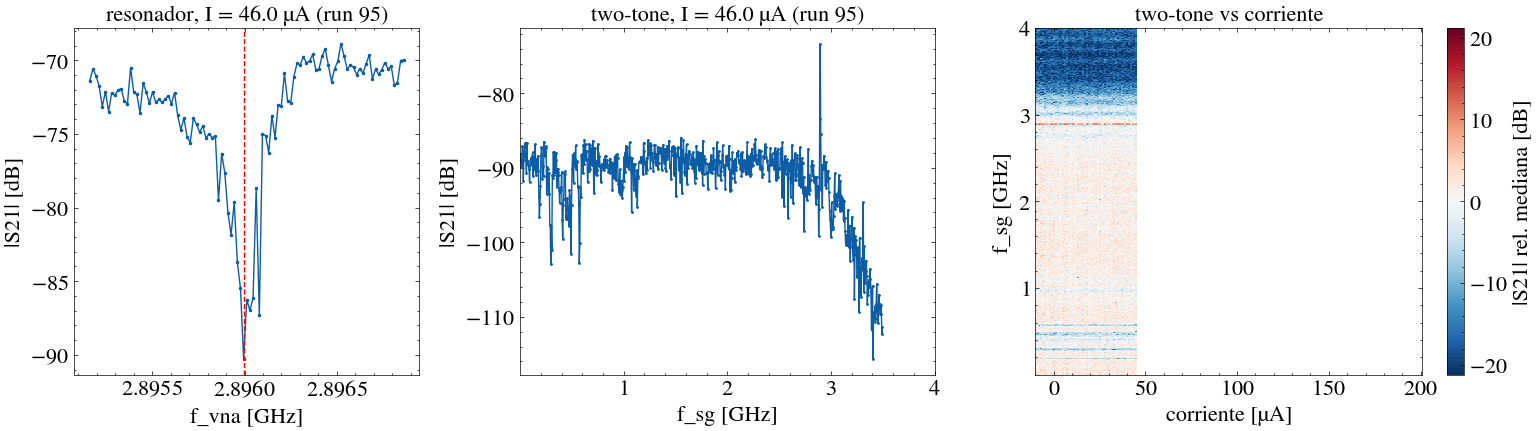

Starting experimental run with id: 39. 
I =   -10.00 uA (1/212) | run 39 | f_cw = 2.896012 GHz | 17.9 min, faltan ~3777 min
Starting experimental run with id: 40. 
I =    -9.00 uA (2/212) | run 40 | f_cw = 2.896012 GHz | 35.6 min, faltan ~3738 min
Starting experimental run with id: 41. 
I =    -8.00 uA (3/212) | run 41 | f_cw = 2.896029 GHz | 53.0 min, faltan ~3690 min
Starting experimental run with id: 42. 
I =    -7.00 uA (4/212) | run 42 | f_cw = 2.896029 GHz | 69.5 min, faltan ~3615 min
Starting experimental run with id: 43. 
I =    -6.00 uA (5/212) | run 43 | f_cw = 2.896029 GHz | 86.1 min, faltan ~3566 min
Starting experimental run with id: 44. 
I =    -5.00 uA (6/212) | run 44 | f_cw = 2.896029 GHz | 102.7 min, faltan ~3527 min
Starting experimental run with id: 45. 
I =    -4.00 uA (7/212) | run 45 | f_cw = 2.896080 GHz | 119.4 min, faltan ~3495 min
Starting experimental run with id: 46. 
I =    -3.00 uA (8/212) | run 46 | f_cw = 2.896029 GHz | 135.8 min, faltan ~3463 min
Start

[pna_tr1(KeysightPNATrace)] User abort detected. 
An exception occurred in measurement with guid: 3db29dea-0000-0000-0000-01a135ec2062;
Traceback:
Traceback (most recent call last):
  File "C:\Users\Leandro\AppData\Local\Temp\ipykernel_11784\793647282.py", line 188, in <module>
    traces.tr1.run_sweep()
  File "c:\Users\Leandro\anaconda3\envs\quantum\lib\site-packages\qcodes\instrument_drivers\Keysight\N52xx.py", line 332, in run_sweep
    time.sleep(0.1)
KeyboardInterrupt



runs: 39 a 95  (57 corrientes)


KeyboardInterrupt: 

In [ ]:
## Two-tone vs flujo. Para CADA corriente de la bobina se crea UN run (un id) con:
##   1) VNA en LIN (SG apagado) -> traza del resonador y mínimo del dip
##   2) VNA en CW en ese mínimo -> barrido de frecuencia del SG (two-tone)
## Cada run se cierra y se guarda al terminar su corriente.
import time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from qcodes.dataset import Measurement, load_by_id

# ---------------- Parámetros ----------------
## corriente (bobina)
I_start = -10e-6          # A
I_stop  = 200e-6          # A (incluido)
I_step  = 1e-6            # A
currents = np.arange(I_start, I_stop + I_step, I_step)
wait_I  = 0.05            # s, estabilización después de cambiar la corriente
rampa_paso = None         # A, rampa hasta I_start (None = directo)
volver_a_cero = False

## vna: barrido lineal para encontrar el resonador
f0_vna   = 5.411765e9     # Hz, centro inicial
span_vna = 10e6          # Hz
N_points = 101
bw_lin   = 10             # Hz
pow_vna  = 0.0            # dBm
att_vna  = -62
seguir   = True           # recentra la ventana LIN en el último f_min

## vna: CW durante el two-tone
bw_cw    = 1              # Hz
pow_cw   = pow_vna        # dBm
N        = 1              # promedios (los hace el VNA)

## sg
pw_sg  = 10               # dBm
att_sg = 0
start  = 1e6              # Hz
stop   = 4e9
step   = 5e6
freq_sig = np.arange(start, stop + step, step)
wait   = 0.01             # s, asentamiento del SG

## gráfico en vivo
actualizar_cada = 20      # redibuja la traza del two-tone cada N puntos del SG
# --------------------------------------------


def rampa_corriente(objetivo, paso=rampa_paso, espera=0.05):
    if paso is None:
        keithley.set_current(float(objetivo)); return
    try:
        actual = float(keithley.get_current())
    except Exception:
        actual = 0.0
    n = max(int(np.ceil(abs(objetivo - actual) / paso)), 1)
    for i_ in np.linspace(actual, objetivo, n + 1)[1:]:
        keithley.set_current(float(i_)); time.sleep(espera)


def minimo_dip(f, mag):
    """f del mínimo de |S21|."""
    i = int(np.argmin(mag))
    return f[i]


def medicion_corriente(c_uA):
    """Un Measurement por corriente: resonador (vs f_vna) + two-tone (vs f_sg)."""
    m = Measurement(name=f'two_tone_I_{c_uA:.2f}uA')
    m.write_period = 1                                    # escribe en la base cada 1 s
    m.register_custom_parameter('f_vna', label='VNA frequency', unit='GHz')
    m.register_custom_parameter('s21_mag_res', label='S21 magnitude (resonador)', unit='dB', setpoints=('f_vna',))
    m.register_custom_parameter('s21_phase_res', label='S21 phase (resonador)', unit='deg', setpoints=('f_vna',))
    m.register_custom_parameter('f_sg', label='SG frequency', unit='GHz')
    m.register_custom_parameter('s21_mag', label='S21 magnitude', unit='dB', setpoints=('f_sg',))
    m.register_custom_parameter('s21_phase', label='S21 phase', unit='deg', setpoints=('f_sg',))
    return m


traces = pna.traces
prev_mode = pna.sweep_mode()
centro = f0_vna
ids = {}                                                  # corriente [uA] -> run_id

meta = dict(span_vna=span_vna, N_points=N_points, bw_lin=bw_lin, pow_vna=pow_vna, att_vna=att_vna,
            bw_cw=bw_cw, pow_cw=pow_cw, pow_sg=pw_sg, att_sg=att_sg, N_average=N,
            f0_vna_inicial=f0_vna, seguir=int(seguir), wait_I=wait_I, wait_sg=wait)

print(f'{len(currents)} corrientes x ({N_points} pts LIN + {len(freq_sig)} pts SG)')

# ============ GRÁFICO EN TIEMPO REAL ============
plt.ioff()
fig_v, axv = plt.subplots(1, 3, figsize=(16, 4.5), gridspec_kw=dict(width_ratios=[1, 1.2, 1.4]))

ln_res, = axv[0].plot([], [], '.-', ms=3)
vl_res = axv[0].axvline(f0_vna / 1e9, color='r', ls='--', lw=1)
axv[0].set_xlabel('f_vna [GHz]'); axv[0].set_ylabel('|S21| [dB]'); axv[0].set_title('resonador')

ln_tt, = axv[1].plot([], [], '.-', ms=2)
axv[1].set_xlim(freq_sig[0] / 1e9, freq_sig[-1] / 1e9)
axv[1].set_xlabel('f_sg [GHz]'); axv[1].set_ylabel('|S21| [dB]'); axv[1].set_title('two-tone')

orden = np.argsort(currents)
TT = np.full((len(freq_sig), len(currents)), np.nan)
im_tt = axv[2].imshow(TT, aspect='auto', origin='lower', cmap='RdBu_r', interpolation='nearest',
                      extent=[currents.min() * 1e6, currents.max() * 1e6,
                              freq_sig[0] / 1e9, freq_sig[-1] / 1e9])
fig_v.colorbar(im_tt, ax=axv[2], label='|S21| rel. mediana [dB]')
axv[2].set_xlabel('corriente [µA]'); axv[2].set_ylabel('f_sg [GHz]'); axv[2].set_title('two-tone vs corriente')
fig_v.tight_layout()
vivo = display(fig_v, display_id=True)


def refrescar():
    for a in axv[:2]:
        a.relim(); a.autoscale_view()
    axv[1].set_xlim(freq_sig[0] / 1e9, freq_sig[-1] / 1e9)
    if vivo is not None:
        vivo.update(fig_v)


def actualizar_mapa():
    Z = TT - np.nanmedian(TT, axis=0, keepdims=True)
    if np.isfinite(Z).any():
        lim = np.nanpercentile(np.abs(Z), 98) or 1
        im_tt.set_data(Z[:, orden])
        im_tt.set_clim(-lim, lim)
# ================================================

try:
    sg.rf_output(False)
    sg.power(pw_sg)
    pna.auto_sweep(False)
    pna.averages(N); pna.averages_enabled(N > 1)
    rampa_corriente(currents[0])
    time.sleep(1.0)
    t0 = time.time()

    for k, c in enumerate(currents):
        c_uA = c * 1e6
        keithley.set_current(float(c))
        time.sleep(wait_I)

        with medicion_corriente(c_uA).run() as ds:        # <-- UN run por corriente
            rid = ds.run_id
            ids[round(c_uA, 4)] = rid
            for key, v in meta.items():
                ds.dataset.add_metadata(key, v)
            ds.dataset.add_metadata('current_uA', c_uA)

            # ---------- 1) resonador: LIN, SG apagado ----------
            sg.rf_output(False)
            pna.sweep_type('LIN')
            set_params(center=centro, span=span_vna, power=pow_vna, bw=bw_lin, N_points=N_points)
            set_params(center=centro, span=span_vna, power=pow_vna, bw=bw_lin, N_points=N_points)

            f_vna = pna.frequency_axis()
            traces.tr1.run_sweep()
            mag = traces.tr1.magnitude()
            pha = traces.tr2.phase()
            ds.add_result(('f_vna', f_vna / 1e9), ('s21_mag_res', mag), ('s21_phase_res', pha))

            f_min = minimo_dip(f_vna, mag)
            ok = 0 < int(np.argmin(mag)) < len(mag) - 1
            if seguir:
                centro = f_min
            ds.dataset.add_metadata('f_cw', f_min)
            ds.dataset.add_metadata('dip_ok', int(ok))

            # vivo: resonador de esta corriente
            ln_res.set_data(f_vna / 1e9, mag)
            vl_res.set_xdata([f_min / 1e9, f_min / 1e9])
            axv[0].set_title(f'resonador, I = {c_uA:.1f} µA (run {rid})')
            ln_tt.set_data([], [])
            axv[1].set_title(f'two-tone, I = {c_uA:.1f} µA (run {rid})')
            refrescar()

            # ---------- 2) two-tone: CW en f_min, barrido SG ----------
            pna.sweep_type('CW')
            pna.cw(f_min)
            pna.points(1)
            pna.if_bandwidth(bw_cw)
            pna.power(pow_cw)
            sg.rf_output(True)
            for j, f in enumerate(freq_sig):
                sg.frequency(f)
                time.sleep(wait)
                traces.tr1.run_sweep()
                m_j = float(np.mean(traces.tr1.magnitude()))
                ds.add_result(('f_sg', f / 1e9), ('s21_mag', m_j),
                              ('s21_phase', float(np.mean(traces.tr2.phase()))))

                TT[j, k] = m_j
                if (j + 1) % actualizar_cada == 0 or j == len(freq_sig) - 1:
                    ln_tt.set_data(freq_sig[:j + 1] / 1e9, TT[:j + 1, k])
                    refrescar()
            sg.rf_output(False)
        # al salir del with, este run queda cerrado y guardado

        actualizar_mapa()
        refrescar()

        el = time.time() - t0
        rest = el / (k + 1) * (len(currents) - k - 1)
        print(f'I = {c_uA:8.2f} uA ({k + 1}/{len(currents)}) | run {rid} | f_cw = {f_min/1e9:.6f} GHz | '
              f'{el / 60:.1f} min, faltan ~{rest / 60:.0f} min')

finally:
    sg.rf_output(False)
    pna.auto_sweep(True)
    pna.sweep_mode(prev_mode)
    if volver_a_cero:
        rampa_corriente(0.0)
    if ids:
        print(f'runs: {min(ids.values())} a {max(ids.values())}  ({len(ids)} corrientes)')